# Step One. Loading, Checking, and Cleaning the Data 

In [1]:
# Loading the libraries 
import pandas as pd
import numpy as np
import seaborn as sn
import matplotlib.pyplot as plt

In [2]:
data = pd.read_csv('ANCinternship.csv')
data.head()

,Age_Group,Region,Residence,Mothereducation,Marritalstatus,Motherwork,ANC,Wealthindex,Parity,Healthcar_access,Birthorder,Age_birth,Age_marriage
0,30 - 34,Awdal,Urban,No Education,Married,No,complete ANC visits,Middle,Primipara,Problem,1-2,21-31,12-33
1,35 - 39,Awdal,Urban,No Education,Married,No,incomplete ANC visits,Middle,Primipara,Problem,4+,21-31,12-33
2,20 - 24,Awdal,Urban,Secondary,Married,No,incomplete ANC visits,Rich,Primipara,Problem,1-2,7-20,12-33
3,20 - 24,Awdal,Urban,Primary,Married,No,incomplete ANC visits,Middle,Primipara,No problem,1-2,7-20,12-33
4,40 - 44,Awdal,Urban,Primary,Married,No,incomplete ANC visits,Poor,Primipara,No problem,1-2,21-31,12-33


In [3]:
data.isnull().sum()

Age_Group           0
Region              0
Residence           0
Mothereducation     0
Marritalstatus      0
Motherwork          0
ANC                 0
Wealthindex         0
Parity              0
Healthcar_access    0
Birthorder          0
Age_birth           0
Age_marriage        0
dtype: int64

In [4]:
data.shape

(8179, 13)

In [5]:
print(data.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8179 entries, 0 to 8178
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   Age_Group         8179 non-null   object
 1   Region            8179 non-null   object
 2   Residence         8179 non-null   object
 3   Mothereducation   8179 non-null   object
 4   Marritalstatus    8179 non-null   object
 5   Motherwork        8179 non-null   object
 6   ANC               8179 non-null   object
 7   Wealthindex       8179 non-null   object
 8   Parity            8179 non-null   object
 9   Healthcar_access  8179 non-null   object
 10  Birthorder        8179 non-null   object
 11  Age_birth         8179 non-null   object
 12  Age_marriage      8179 non-null   object
dtypes: object(13)
memory usage: 830.8+ KB
None


In [6]:
print(data.duplicated().sum())

3444


In [7]:
data = data.drop_duplicates()

In [8]:
print(data.duplicated().sum())

0


In [9]:
x = data.drop(columns=['ANC'])
y = data['ANC']

In [10]:
x.head()

,Age_Group,Region,Residence,Mothereducation,Marritalstatus,Motherwork,Wealthindex,Parity,Healthcar_access,Birthorder,Age_birth,Age_marriage
0,30 - 34,Awdal,Urban,No Education,Married,No,Middle,Primipara,Problem,1-2,21-31,12-33
1,35 - 39,Awdal,Urban,No Education,Married,No,Middle,Primipara,Problem,4+,21-31,12-33
2,20 - 24,Awdal,Urban,Secondary,Married,No,Rich,Primipara,Problem,1-2,7-20,12-33
3,20 - 24,Awdal,Urban,Primary,Married,No,Middle,Primipara,No problem,1-2,7-20,12-33
4,40 - 44,Awdal,Urban,Primary,Married,No,Poor,Primipara,No problem,1-2,21-31,12-33


In [11]:
y.head()

0       complete ANC visits
1     incomplete ANC visits
2     incomplete ANC visits
3     incomplete ANC visits
4     incomplete ANC visits
Name: ANC, dtype: object

In [12]:
y

0          complete ANC visits
1        incomplete ANC visits
2        incomplete ANC visits
3        incomplete ANC visits
4        incomplete ANC visits
                 ...          
8172     incomplete ANC visits
8173     incomplete ANC visits
8174     incomplete ANC visits
8176     incomplete ANC visits
8177     incomplete ANC visits
Name: ANC, Length: 4735, dtype: object

# Step Two. Data Preprocessing 

In [13]:
# Loading libraries for data preprocessing
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder

In [14]:
# Define ID and label columns
idcol = None  # No ID column in your ANC data
labelcol = "ANC"  # Target variable

# Define feature columns (True for categorical, False for numeric)
cols = (
    ("Age_Group", True),
    ("Region", True),
    ("Residence", True),
    ("Mothereducation", True),
    ("Marritalstatus", True),
    ("Motherwork", True),
    ("Wealthindex", True),
    ("Parity", True),
    ("Healthcar_access", True),
    ("Birthorder", True),
    ("Age_birth", True),
    ("Age_marriage", True),
)

# === Data Cleaning Functions ===

def drop_non_features(data, cols):
    return data[[c for c, _ in cols]]

def drop_missing(data):
    """Remove rows with missing values"""
    return data.replace(r"^\s*$", np.nan, regex=True).dropna()

def clean(data):
    """Drop ID column if it exists"""
    if idcol and idcol in data.columns:
        data.drop([idcol], axis=1, inplace=True)

def categorize(data, cols):
    catcols = (c for c, iscat in cols if iscat)
    for col in catcols:
        data[col] = pd.Categorical(data[col])
    return data

def splitdf(data, label):
    return data.drop(label, axis=1), data[label]

def load_dataset(file_path):
    """Load and prepare ANC dataset"""
    data = pd.read_csv(file_path)
    data = drop_missing(data).reset_index(drop=True)
    clean(data)
    features, labels = splitdf(data, labelcol)
    features = drop_non_features(features, cols)
    features = categorize(features, cols)
    labels = labels == "complete ANC visits"  # Boolean target
    return features, labels

def setup_plot():
    plt.rcParams["axes.grid.axis"] = "y"
    plt.rcParams["axes.grid"] = True
    plt.rcParams["legend.fontsize"] = 14
    plt.rc("grid", linestyle="dashed", color="lightgrey", linewidth=1)
    plt.rcParams["xtick.labelsize"] = 15
    plt.rcParams["ytick.labelsize"] = 15

In [15]:
def load_dataset():
    data = pd.read_csv("ANCinternship.csv")
    labels = data["ANC"]  # Replace with your actual label column
    data = data.drop(columns=["ANC"])  # Drop label from features
    return data, labels

In [16]:
data, labels = load_dataset()

# Get categorical column indexes
cat_columns_ix_ = {
    c: i
    for i, c in enumerate(data.columns)
    if pd.api.types.is_categorical_dtype(data[c])
}
# categorical column names
cat_columns = [c for c in (data.columns) if pd.api.types.is_categorical_dtype(data[c])]

# Make copies of data with various representations for categorical features.
data_numeric = data.copy()  # categorical fields are label encoded but numerical
data_categorical = (
    data.copy()
)  # categorical fields are label encoded, numeric but categorical type
data_ohe = pd.get_dummies(
    data, columns=cat_columns, sparse=False
)  # categorical fields are one hot encoded

# Convert categorical columns to numeric encoded labels
for col in cat_columns:
    data_numeric[col] = LabelEncoder().fit_transform(data_numeric[col])
    data_categorical[col] = data_numeric[col].astype("category")


# Set data used for explorations
current_data = data_categorical
print("Available features: \n", list(data_categorical.columns))
print("Label Balance - [Complete ANC, incomplete ANC] : ", list(labels.value_counts()))

Available features: 
 ['Age_Group', 'Region', 'Residence', 'Mothereducation', 'Marritalstatus', 'Motherwork', 'Wealthindex', 'Parity', 'Healthcar_access', 'Birthorder', 'Age_birth', 'Age_marriage']
Label Balance - [Complete ANC, incomplete ANC] :  [7512, 667]


# Step Three. Training and Evualating Models

In [17]:
# Loading libraries for building and evaluating models 
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import shap
import time 
from lime.lime_tabular import LimeTabularExplainer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

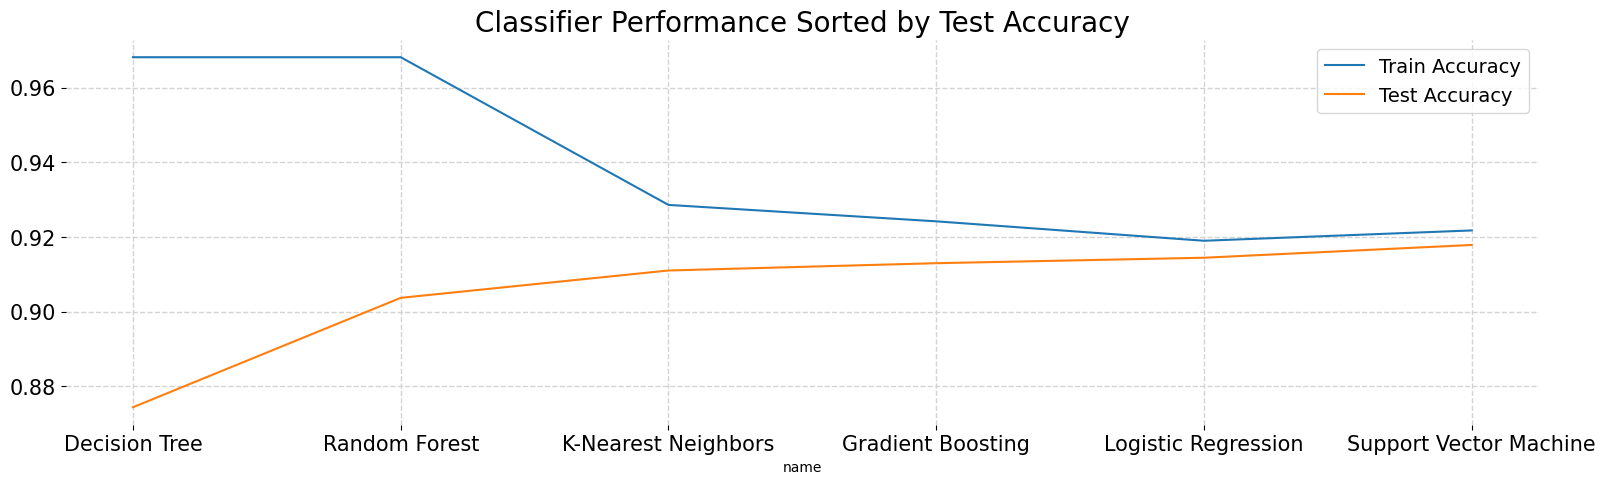

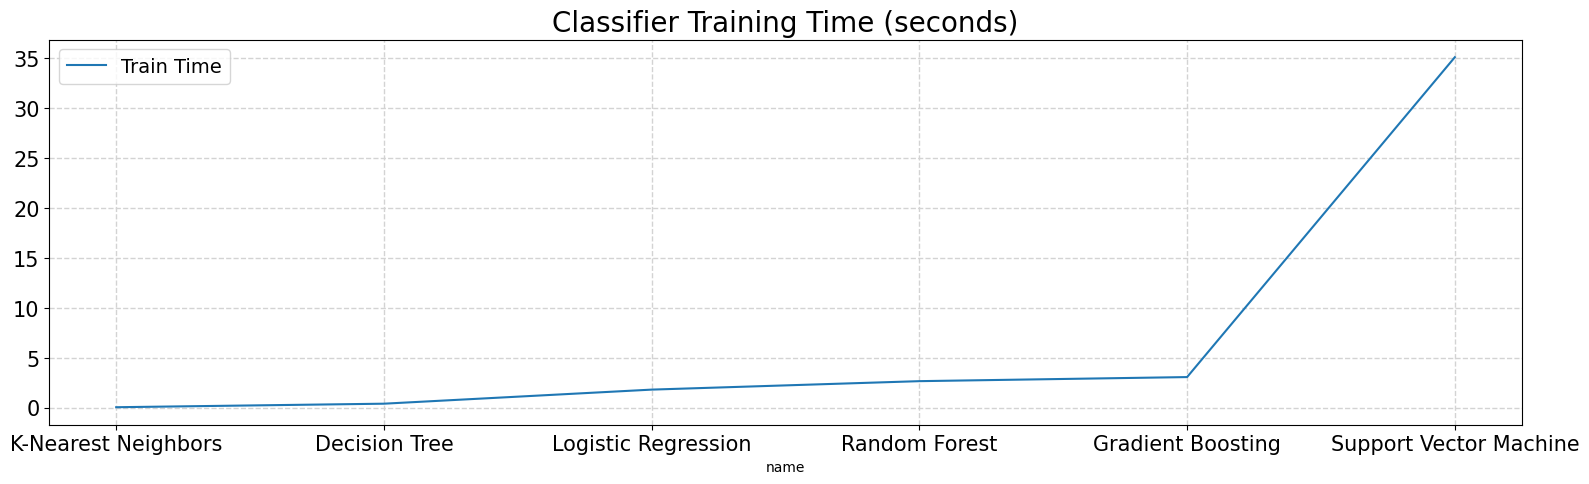

In [18]:
# Use the one-hot encoded data
processed_data = pd.get_dummies(current_data)

trained_models = []  # keeping track of all details for models we train

def train_model(model, data, labels): 
    X = data
    y = labels.values
    X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

    pipe = Pipeline([('scaler', StandardScaler()), ('clf', model["clf"])])

    start_time = time.time()
    pipe.fit(X_train, y_train)
    train_time = time.time() - start_time

    train_accuracy = pipe.score(X_train, y_train)
    test_accuracy = pipe.score(X_test, y_test) 

    model_details = {
        "name": model["name"],
        "train_accuracy": train_accuracy,
        "test_accuracy": test_accuracy,
        "train_time": train_time,
        "model": pipe
    }
    return model_details

models = [
    {"name": "Decision Tree", "clf": DecisionTreeClassifier()},
    {"name": "Logistic Regression", "clf": LogisticRegression(max_iter=1000)},
    {"name": "Random Forest", "clf": RandomForestClassifier(n_estimators=100)},
    {"name": "K-Nearest Neighbors", "clf": KNeighborsClassifier()},
    {"name": "Gradient Boosting", "clf": GradientBoostingClassifier(n_estimators=100)},
    {"name": "Support Vector Machine", "clf": SVC(probability=True)}
]

for model in models:
    model_details = train_model(model, processed_data, labels)
    trained_models.append(model_details)

# visualize accuracy and run time
setup_plot()
model_df = pd.DataFrame(trained_models)
model_df.sort_values("test_accuracy", inplace=True) 
ax = model_df[["train_accuracy", "test_accuracy", "name"]].plot(
    kind="line", x="name", figsize=(19, 5), title="Classifier Performance Sorted by Test Accuracy"
)
ax.legend(["Train Accuracy", "Test Accuracy"])
ax.title.set_size(20)
plt.box(False)

model_df.sort_values("train_time", inplace=True)
ax = model_df[["train_time", "name"]].plot(
    kind="line", x="name", figsize=(19, 5), grid=True, title="Classifier Training Time (seconds)"
)
ax.title.set_size(20)
ax.legend(["Train Time"])

In [ ]:
# Model = KNN

In [19]:
# One-hot encode your features to convert categorical text to numbers
x = pd.get_dummies(current_data)

# Split the processed data into training and testing sets
x_train, x_test, y_train, y_test = train_test_split(x, labels, random_state=42)

# KNN
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=7)

# Train the model
knn.fit(x_train, y_train)

# Predict the outcome using testing data
knn_predictions = knn.predict(x_test)

# Evaluate the model by comparing the predicted outcome with test outcome
Evaluation_results = accuracy_score(y_test, knn_predictions)

# Print out the accuracy output
print("Accuracy=")
print(Evaluation_results)

Accuracy=
0.9134474327628361


In [20]:
from sklearn.inspection import permutation_importance

# Get the KNN model from trained_models
knn_model = next(m["model"] for m in trained_models if m["name"] == "K-Nearest Neighbors")

# Ensure consistent split
X = processed_data
y = labels.values
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=42)

# Run permutation importance
knn_result = permutation_importance(knn_model, X_test, y_test, n_repeats=10, random_state=42)

# Create DataFrame of feature importances
importance_knn = pd.DataFrame({
    'Feature': X.columns,
    'Importance': knn_result.importances_mean
})

# Sort by importance and select top 10
top10_features_knn = importance_knn.sort_values(by='Importance', ascending=False).head(10)

# Display as clean table
print(top10_features_knn.to_markdown(index=False, numalign="left", stralign="left"))

| Feature                      | Importance   |
|:-----------------------------|:-------------|
| Birthorder_1-2               | 0.00308068   |
| Mothereducation_No Education | 0.00298289   |
| Mothereducation_Primary      | 0.00273839   |
| Age_Group_35 - 39            | 0.00244499   |
| Age_Group_15 - 19            | 0.00234719   |
| Region_Awdal                 | 0.00210269   |
| Region_Togdheer              | 0.00205379   |
| Residence_Urban              | 0.00190709   |
| Wealthindex_Poor             | 0.00166259   |
| Birthorder_3                 | 0.00156479   |


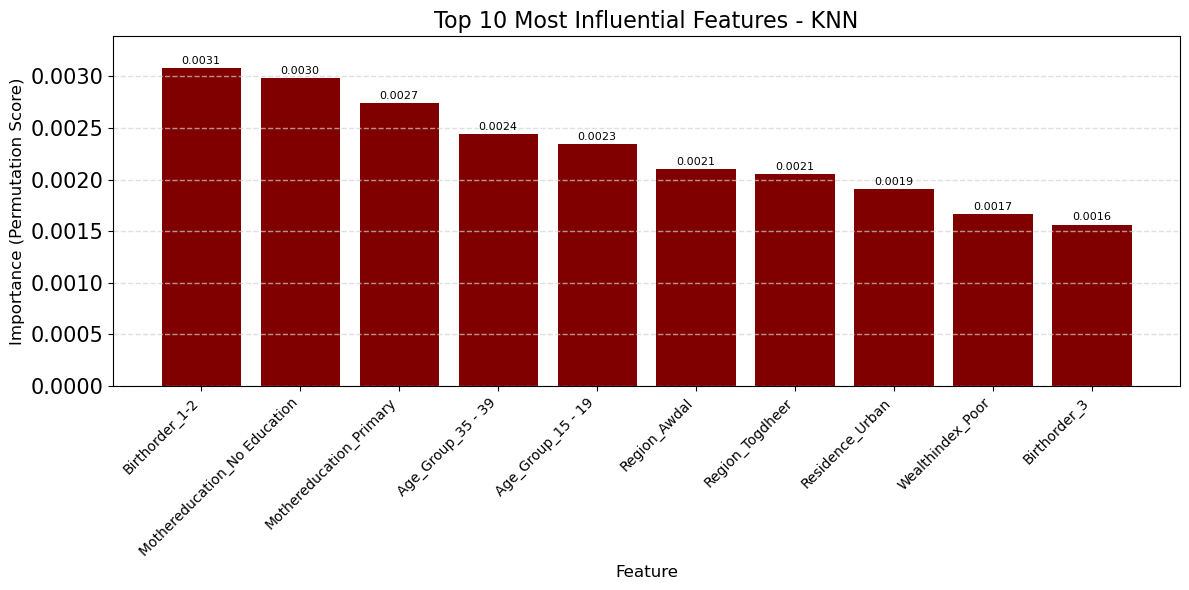

In [27]:
# Sort and select the top 10 most important features
importance_knn_sorted = importance_knn.sort_values(by='Importance', ascending=False).head(10)

# Plot
plt.figure(figsize=(12, 6))
bars = plt.bar(importance_knn_sorted['Feature'], importance_knn_sorted['Importance'], color='maroon')
plt.title("Top 10 Most Influential Features - KNN", fontsize=16)
plt.xlabel("Feature", fontsize=12)
plt.ylabel("Importance (Permutation Score)", fontsize=12)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.ylim(0, importance_knn_sorted['Importance'].max() * 1.1)  # Dynamic upper limit

# Annotate bars with values
for bar in bars:
    height = bar.get_height()
    plt.annotate(f'{height:.4f}', xy=(bar.get_x() + bar.get_width() / 2, height),
                 xytext=(0, 3), textcoords="offset points", ha='center', fontsize=8)
plt.tight_layout()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

In [21]:
# Make predictions on the test set
y_pred_knn = knn.predict(x_test)

# 1. Predict Probabilities
y_proba_knn = knn.predict_proba(x_test)[:, 1]  # Probabilities for the positive class

# Calculate and print evaluation metrics
accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, 
                            average='weighted')
recall_knn = recall_score(y_test, y_pred_knn, 
                        average='weighted')
f1_knn = f1_score(y_test, y_pred_knn, average='weighted')
auc_knn = roc_auc_score(y_test, y_proba_knn)

print("K-Nearest Neighbor ")
print(f"Accuracy: {accuracy_knn:.4f}")
print(f"Precision: {precision_knn:.4f}")
print(f"Recall: {recall_knn:.4f}")
print(f"F1-Score: {f1_knn:.4f}")
print(f'ROC AUC: {auc_knn:.4f}')

K-Nearest Neighbor 
Accuracy: 0.9134
Precision: 0.8718
Recall: 0.9134
F1-Score: 0.8825
ROC AUC: 0.6489


In [ ]:
# Model = Logistic Regression

Model: Logistic Regression (Top 10 Features)
Accuracy: 0.9144
Precision: 0.8711
Recall: 0.9144
F1-Score: 0.8815
ROC AUC: 0.8096


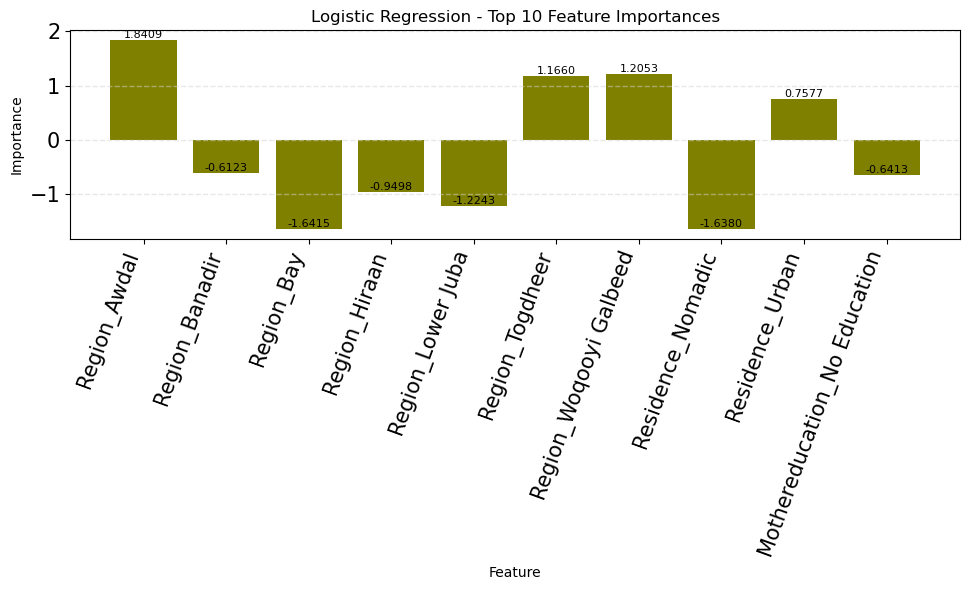

In [22]:
# Train initial model on all features
LogReg = LogisticRegression(max_iter=1000)
LogReg.fit(x_train, y_train)

# Get feature importances
importances = LogReg.coef_[0]
importance_lr = pd.DataFrame({'Feature': x_train.columns, 'Importance': importances})

# Select top 10 features (based on absolute importance)
top_10_features = importance_lr.reindex(
    importance_lr['Importance'].abs().sort_values(ascending=False).index
).head(10)['Feature'].tolist()

# Re-train model using only top 10 features
LogReg_top10 = LogisticRegression(max_iter=1000)
LogReg_top10.fit(x_train[top_10_features], y_train)

# Make predictions using top 10 features
y_pred_lr = LogReg_top10.predict(x_test[top_10_features])
y_proba_lr = LogReg_top10.predict_proba(x_test[top_10_features])[:, 1]

# Evaluation
accuracy_lr = accuracy_score(y_test, y_pred_lr)
precision_lr = precision_score(y_test, y_pred_lr, average='weighted')
recall_lr = recall_score(y_test, y_pred_lr, average='weighted')
f1_lr = f1_score(y_test, y_pred_lr, average='weighted')
auc_lr = roc_auc_score(y_test, y_proba_lr)

# Print results
print("Model: Logistic Regression (Top 10 Features)")
print(f"Accuracy: {accuracy_lr:.4f}")
print(f"Precision: {precision_lr:.4f}")
print(f"Recall: {recall_lr:.4f}")
print(f"F1-Score: {f1_lr:.4f}")
print(f"ROC AUC: {auc_lr:.4f}")

# Plot top 10 feature importances
importance_top10 = importance_lr[importance_lr['Feature'].isin(top_10_features)]
plt.figure(figsize=(10, 6))
plt.bar(importance_top10['Feature'], importance_top10['Importance'], color='olive')
plt.title("Logistic Regression - Top 10 Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=70, ha="right")
plt.grid(axis='y', linestyle='--', alpha=0.5)
for i, val in enumerate(importance_top10['Importance']):
    plt.text(i, val, f'{val:.4f}', ha='center', va='bottom', fontsize=8)
plt.tight_layout()
plt.savefig('logistic_regression_top10_feature_importance.png')
plt.show()

In [ ]:
# Model = DT

| Feature                     | Importance   |
|:----------------------------|:-------------|
| Healthcar_access_No problem | 0.0560686    |
| Birthorder_1-2              | 0.0493647    |
| Age_birth_7-20              | 0.0486213    |
| Healthcar_access_Problem    | 0.0460609    |
| Wealthindex_Rich            | 0.0443058    |
| Birthorder_3                | 0.0437344    |
| Region_Awdal                | 0.0432318    |
| Residence_Urban             | 0.0423721    |
| Age_Group_30 - 34           | 0.0383365    |
| Age_Group_25 - 29           | 0.0378799    |
Decision Tree
Accuracy: 0.9169
Precision: 0.8819
Recall: 0.9169
F1-Score: 0.8829
ROC AUC: 0.6629


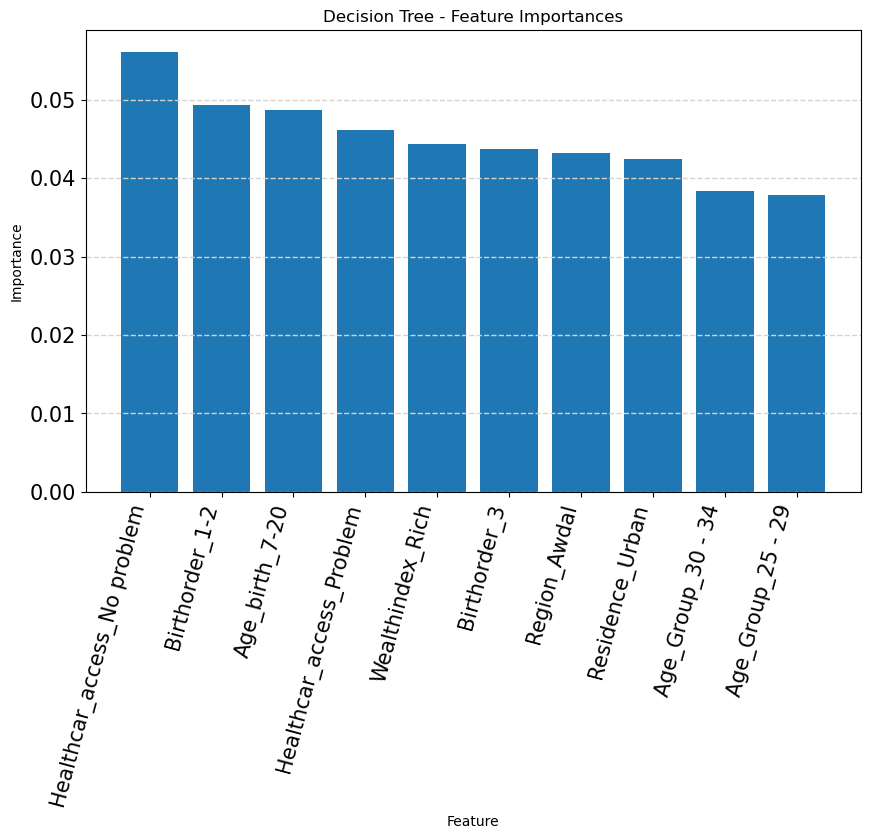

In [23]:
Dt_model = DecisionTreeClassifier()

# Training initial model on all features to get importances
Dt_model.fit(x_train, y_train)

# Extract the key factors
importance_dt = Dt_model.feature_importances_

# Put the extracted key factors in a table
importance_dt = pd.DataFrame({'Feature': x.columns,
                              'Importance': importance_dt})

# Sort by importance and visualize (optional)
importance_dt = importance_dt.sort_values(by='Importance', 
                                          ascending=False)
print(importance_dt.head(10).to_markdown(index=False, 
                                         numalign="left", stralign="left"))

# Select top 10 features
top_10_features_dt = importance_dt.head(10)['Feature'].tolist()

# Re-train model using only top 10 features
Dt_model = DecisionTreeClassifier()
Dt_model.fit(x_train[top_10_features_dt], y_train)

# Make predictions on the test set using top 10 features
y_pred_dt = Dt_model.predict(x_test[top_10_features_dt])

# 1. Predict Probabilities
y_proba_dt = Dt_model.predict_proba(x_test[top_10_features_dt])[:, 1]

# Calculate and print evaluation metrics
accuracy_dt = accuracy_score(y_test, y_pred_dt)
precision_dt = precision_score(y_test, y_pred_dt, average='weighted')
recall_dt = recall_score(y_test, y_pred_dt, average='weighted')
f1_dt = f1_score(y_test, y_pred_dt, average='weighted')
auc_dt = roc_auc_score(y_test, y_proba_dt)

print("Decision Tree")
print(f"Accuracy: {accuracy_dt:.4f}")
print(f"Precision: {precision_dt:.4f}")
print(f"Recall: {recall_dt:.4f}")
print(f"F1-Score: {f1_dt:.4f}")
print(f'ROC AUC: {auc_dt:.4f}')

# Plotting feature importances of top 10
importance_dt_top10 = importance_dt[importance_dt['Feature'].isin(top_10_features_dt)]
plt.figure(figsize=(10, 6))  # Adjust the size as needed
plt.bar(importance_dt_top10['Feature'], importance_dt_top10['Importance'])
plt.title("Decision Tree - Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=75, ha="right")  # Rotate x-axis labels for readability
plt.show()  # Display the plot

In [ ]:
# Model = RF

| Feature                | Importance   |
|:-----------------------|:-------------|
| Age_Group_25 - 29      | 0.0468004    |
| Region_Awdal           | 0.0433919    |
| Birthorder_1-2         | 0.0401568    |
| Birthorder_3           | 0.0379764    |
| Age_Group_30 - 34      | 0.036503     |
| Age_Group_20 - 24      | 0.0361526    |
| Age_Group_35 - 39      | 0.0359481    |
| Region_Woqooyi Galbeed | 0.0352425    |
| Age_birth_21-31        | 0.0335062    |
| Age_birth_7-20         | 0.0332298    |
Random Forest
Accuracy: 0.9164
Precision: 0.8698
Recall: 0.9164
F1-Score: 0.8792
ROC AUC: 0.6046


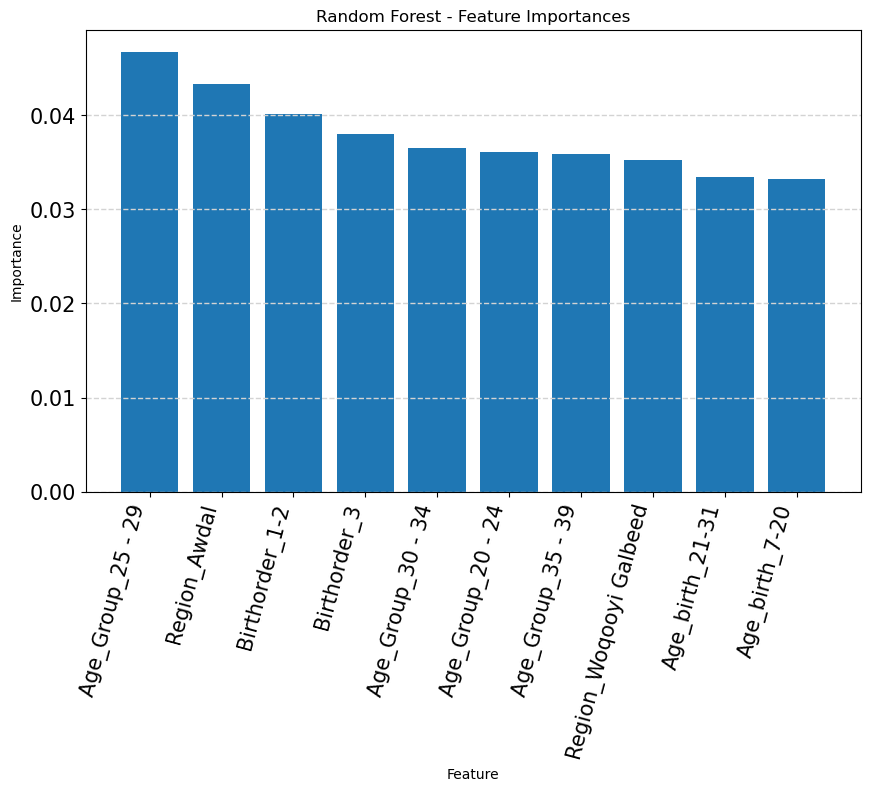

In [24]:
Rf_model = RandomForestClassifier()

# Initial training to extract importances
Rf_model.fit(x_train, y_train)

# Extracting the key factors 
importance_rf = Rf_model.feature_importances_

# Put the extracted key factors in a table 
importance_rf = pd.DataFrame({'Feature': x.columns,
                              'Importance': importance_rf})

# Sort by importance and visualize (optional)
importance_rf = importance_rf.sort_values(by='Importance',
                                          ascending=False)
print(importance_rf.head(10).to_markdown(index=False, 
                                         numalign="left", stralign="left"))

# Select top 10 features
top_10_features_rf = importance_rf.head(10)['Feature'].tolist()

# Re-train the model using only top 10 features
Rf_model = RandomForestClassifier()
Rf_model.fit(x_train[top_10_features_rf], y_train)

# Make predictions on the test set using only top 10 features
y_pred_rf = Rf_model.predict(x_test[top_10_features_rf])

# 1. Predict Probabilities
y_proba_rf = Rf_model.predict_proba(x_test[top_10_features_rf])[:, 1]

# Calculate and print evaluation metrics
accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')
auc_rf = roc_auc_score(y_test, y_proba_rf)

print("Random Forest")
print(f"Accuracy: {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall: {recall_rf:.4f}")
print(f"F1-Score: {f1_rf:.4f}")
print(f'ROC AUC: {auc_rf:.4f}')

# Plotting feature importances of top 10
importance_rf_top10 = importance_rf[importance_rf['Feature'].isin(top_10_features_rf)]
plt.figure(figsize=(10,6))  # Adjust the size as needed
plt.bar(importance_rf_top10['Feature'], importance_rf_top10['Importance'])
plt.title("Random Forest - Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=75, ha="right")  # Rotate x-axis labels for readability
plt.show()  # Display the plot

In [ ]:
# Model = SVM 

| Feature                   | Importance   |
|:--------------------------|:-------------|
| Age_Group_15 - 19         | 0            |
| Parity_Multipara          | 0            |
| Mothereducation_Primary   | 0            |
| Mothereducation_Secondary | 0            |
| Marritalstatus_Divorced   | 0            |
| Marritalstatus_Married    | 0            |
| Marritalstatus_Widowed    | 0            |
| Motherwork_No             | 0            |
| Motherwork_Yes            | 0            |
| Wealthindex_Middle        | 0            |


C:\Users\Dr. Abdalla\Documents\New folder\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Support Vector Machine
Accuracy: 0.9174
Precision: 0.8415
Recall: 0.9174
F1-Score: 0.8778
ROC AUC: 0.4652


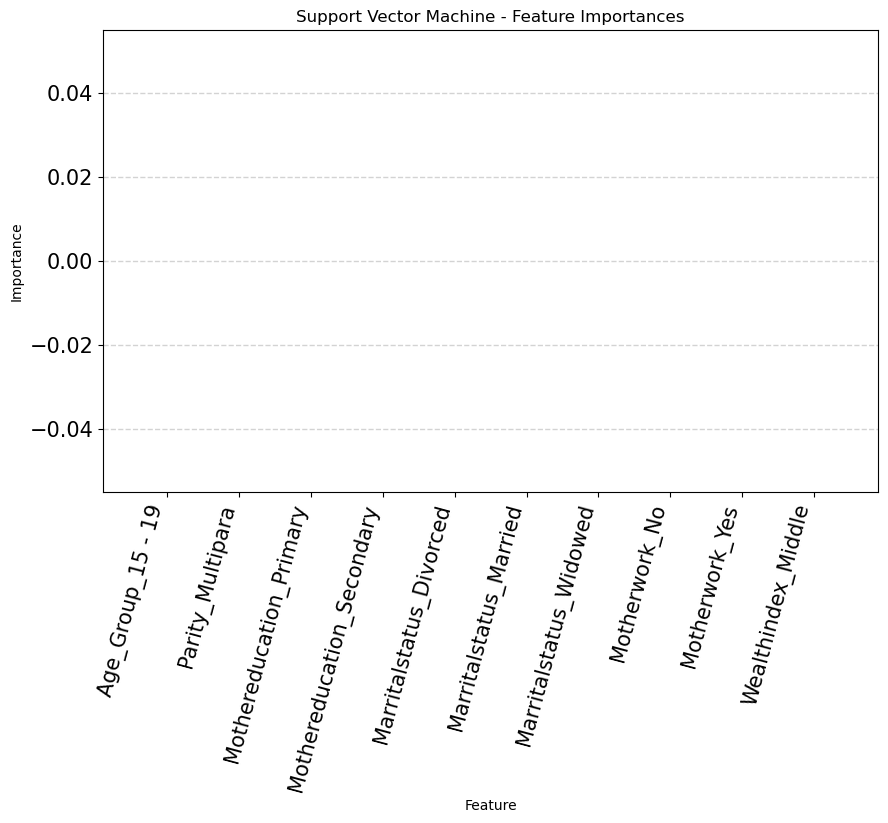

In [25]:
Svm_model = SVC(probability=True)

# Initial training to extract importances
Svm_model.fit(x_train, y_train)

# Extracting the key factors using permutation importance
sv_result = permutation_importance(Svm_model, x_train, y_train,
                                   n_repeats=5, random_state=42, n_jobs=-1)

importance_sv = sv_result.importances_mean

# Put the extracted key factors in a table
importance_sv = pd.DataFrame({'Feature': x.columns,
                              'Importance': importance_sv})

# Sort by importance and visualize (optional)
importance_sv = importance_sv.sort_values(by='Importance',
                                          ascending=False)
print(importance_sv.head(10).to_markdown(index=False,
                                         numalign="left", stralign="left"))

# Select top 10 features
top_10_features_sv = importance_sv.head(10)['Feature'].tolist()

# Re-train the model using only top 10 features
Svm_model = SVC(probability=True)
Svm_model.fit(x_train[top_10_features_sv], y_train)

# Make predictions on the test set using only top 10 features
y_pred_sv = Svm_model.predict(x_test[top_10_features_sv])

# 1. Predict Probabilities
y_proba_sv = Svm_model.predict_proba(x_test[top_10_features_sv])[:, 1]  # Probabilities for the positive class

# Calculate and print evaluation metrics
accuracy_sv = accuracy_score(y_test, y_pred_sv)
precision_sv = precision_score(y_test, y_pred_sv, average='weighted')
recall_sv = recall_score(y_test, y_pred_sv, average='weighted')
f1_sv = f1_score(y_test, y_pred_sv, average='weighted')
auc_sv = roc_auc_score(y_test, y_proba_sv)

print("Support Vector Machine")
print(f"Accuracy: {accuracy_sv:.4f}")
print(f"Precision: {precision_sv:.4f}")
print(f"Recall: {recall_sv:.4f}")
print(f"F1-Score: {f1_sv:.4f}")
print(f'ROC AUC: {auc_sv:.4f}')

# Plotting feature importances of top 10
importance_sv_top10 = importance_sv[importance_sv['Feature'].isin(top_10_features_sv)]
plt.figure(figsize=(10, 6))  # Adjust the size as needed
plt.bar(importance_sv_top10['Feature'], importance_sv_top10['Importance'])
plt.title("Support Vector Machine - Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=75, ha="right")  # Rotate x-axis labels for readability
plt.show()  # Display the plot

In [ ]:
# Model = Gradient Boosting 

| Feature                      | Importance   |
|:-----------------------------|:-------------|
| Region_Awdal                 | 0.170592     |
| Wealthindex_Rich             | 0.124798     |
| Region_Woqooyi Galbeed       | 0.100926     |
| Residence_Nomadic            | 0.100782     |
| Mothereducation_No Education | 0.0776712    |
| Region_Togdheer              | 0.0711761    |
| Mothereducation_Secondary    | 0.03688      |
| Residence_Urban              | 0.0346771    |
| Healthcar_access_Problem     | 0.0248805    |
| Age_Group_25 - 29            | 0.0203684    |
Gradient Boosting
Accuracy: 0.9134
Precision: 0.8733
Recall: 0.9134
F1-Score: 0.8833
ROC AUC: 0.7953


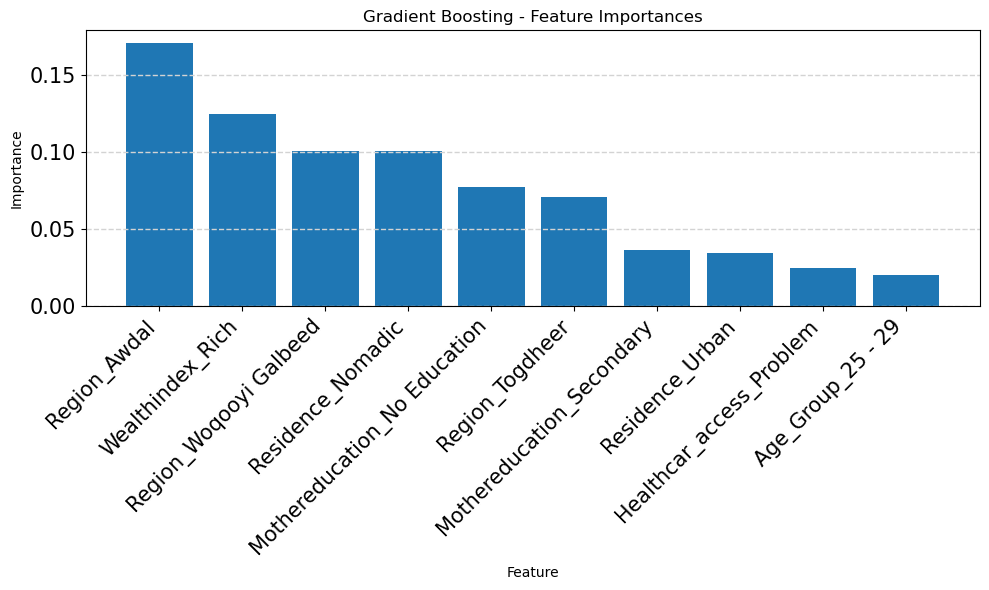

In [26]:
Gb_model = GradientBoostingClassifier(n_estimators=100, 
                    learning_rate=0.1, random_state=42)

# Initial training to extract feature importance
Gb_model.fit(x_train, y_train)

# 8. Feature importance
importance_gb = Gb_model.feature_importances_

# Create a DataFrame for better visualization and sorting
feature_names = x_train.columns  # Assuming x_train is a pandas DataFrame
importance_Gb = pd.DataFrame({'Feature': feature_names,
                              'Importance': importance_gb})

# Sort by importance
importance_Gb = importance_Gb.sort_values(by='Importance',
                                        ascending=False)

# Print top 10 feature importances
print(importance_Gb.head(10).to_markdown(index=False, numalign="left", stralign="left"))

# Select top 10 features
top_10_features_gb = importance_Gb.head(10)['Feature'].tolist()

# Re-train the model using only top 10 features
Gb_model = GradientBoostingClassifier(n_estimators=100, 
                    learning_rate=0.1, random_state=42)
Gb_model.fit(x_train[top_10_features_gb], y_train)

# Make predictions on the test set using top 10 features
y_pred_Gb = Gb_model.predict(x_test[top_10_features_gb])

# Get predicted probabilities
y_proba_gb = Gb_model.predict_proba(x_test[top_10_features_gb])[:, 1]

# Calculate and print evaluation metrics
accuracy_Gb = accuracy_score(y_test, y_pred_Gb)
precision_Gb = precision_score(y_test, y_pred_Gb, average='weighted')
recall_Gb = recall_score(y_test, y_pred_Gb, average='weighted')
f1_Gb = f1_score(y_test, y_pred_Gb, average='weighted')
auc_Gb = roc_auc_score(y_test, y_proba_gb)

print("Gradient Boosting")
print(f"Accuracy: {accuracy_Gb:.4f}")
print(f"Precision: {precision_Gb:.4f}")
print(f"Recall: {recall_Gb:.4f}")
print(f"F1-Score: {f1_Gb:.4f}")
print(f'ROC AUC: {auc_Gb:.4f}')

# Plot feature importances of top 10
importance_Gb_top10 = importance_Gb[importance_Gb['Feature'].isin(top_10_features_gb)]

plt.figure(figsize=(10, 6))
plt.bar(importance_Gb_top10['Feature'], importance_Gb_top10['Importance'])
plt.title("Gradient Boosting - Feature Importances")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [ ]:
# Model accurecy graph 

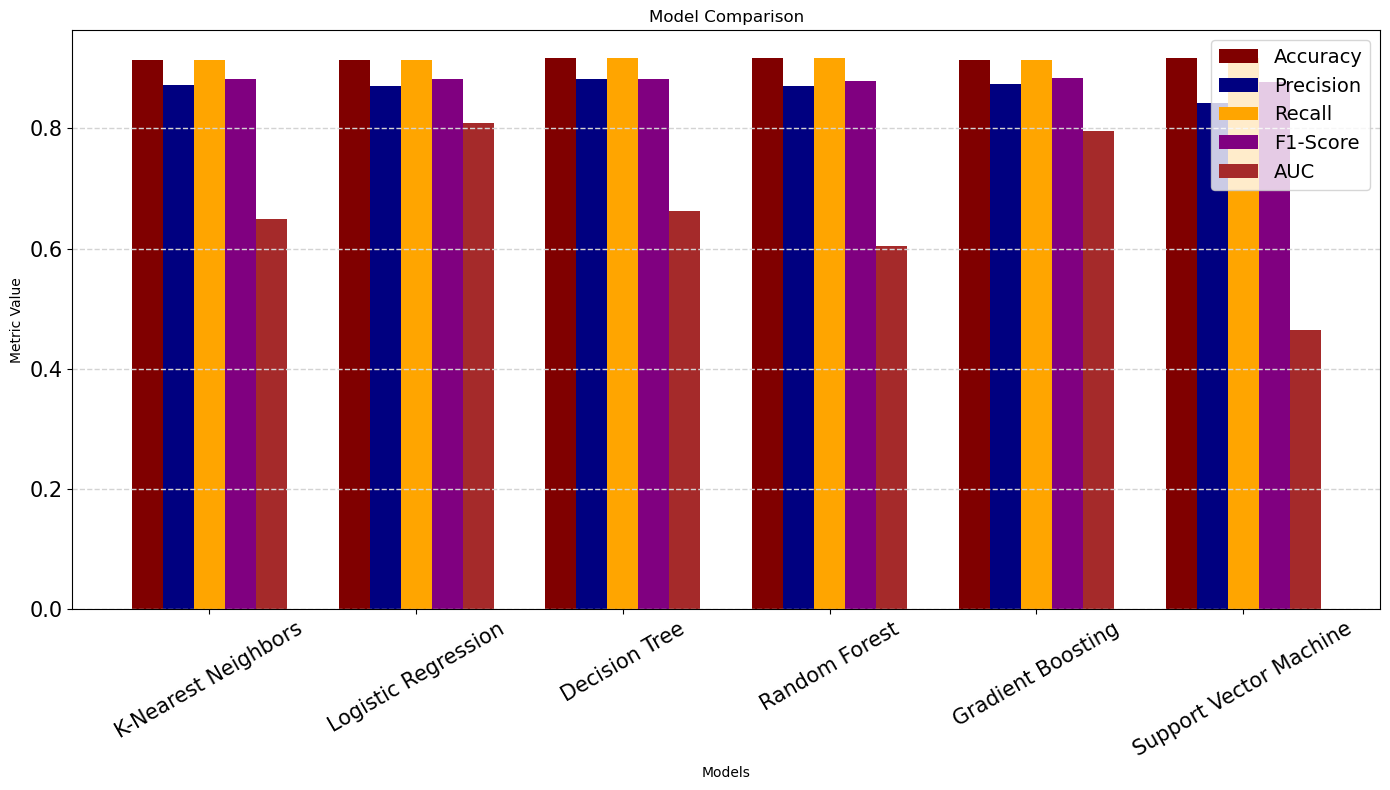

In [27]:
# Define model performance lists
accuracies = [accuracy_knn, accuracy_lr, accuracy_dt, accuracy_rf, accuracy_Gb, accuracy_sv]
precisions = [precision_knn, precision_lr, precision_dt, precision_rf, precision_Gb, precision_sv]
recalls = [recall_knn, recall_lr, recall_dt, recall_rf, recall_Gb, recall_sv]
f1_scores = [f1_knn, f1_lr, f1_dt, f1_rf, f1_Gb, f1_sv]
aucs = [auc_knn, auc_lr, auc_dt, auc_rf, auc_Gb, auc_sv]

metrics = [accuracies, precisions, recalls, f1_scores, aucs]
metric_names = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'AUC']
model_names = ['K-Nearest Neighbors', 'Logistic Regression',
               'Decision Tree', 'Random Forest', 
               'Gradient Boosting', 'Support Vector Machine']

num_models = len(model_names)
num_metrics = len(metric_names)

bar_width = 0.15
index = np.arange(num_models)

# Custom color palette (excluding blue, green, red, yellow)
custom_colors = ['maroon', 'navy', 'orange', 'purple', 'brown']

plt.figure(figsize=(14, 8))

for i in range(num_metrics):
    color = custom_colors[i % len(custom_colors)]  # Cycle through custom colors
    plt.bar(index + i*bar_width, metrics[i], 
            width=bar_width, label=metric_names[i], color=color)

plt.xlabel('Models')
plt.ylabel('Metric Value')
plt.title('Model Comparison')
plt.xticks(index + bar_width * 2, model_names, rotation=30)
plt.legend()
plt.tight_layout()
plt.show()

In [28]:
aucs = [auc_knn, auc_lr, auc_dt, auc_rf, auc_Gb, auc_sv]
aucs

[0.6489115075510024,
 0.8096131767199505,
 0.662922181148358,
 0.6045943149846706,
 0.7952792041483202,
 0.4652082991635231]

In [29]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score
import numpy as np

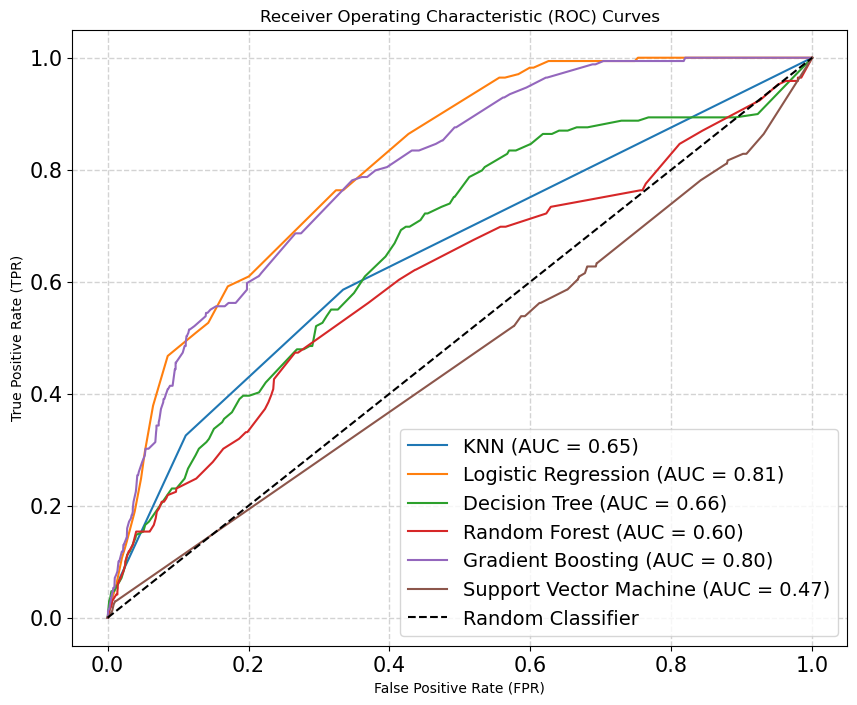

In [30]:
# Convert y_test from string labels to binary: 1 = complete, 0 = incomplete
y_test_binary = np.where(y_test == 'complete ANC visits', 1, 0)

# List of AUC scores (already calculated)
aucs = [auc_knn, auc_lr, auc_dt, auc_rf, auc_Gb, auc_sv]
model_names = ['KNN', 'Logistic Regression', 'Decision Tree', 'Random Forest', 'Gradient Boosting', 'Support Vector Machine']

# Calculate ROC curves using predicted probabilities
fpr_knn, tpr_knn, _ = roc_curve(y_test_binary, y_proba_knn)
fpr_lr, tpr_lr, _ = roc_curve(y_test_binary, y_proba_lr)
fpr_dt, tpr_dt, _ = roc_curve(y_test_binary, y_proba_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test_binary, y_proba_rf)
fpr_gb, tpr_gb, _ = roc_curve(y_test_binary, y_proba_gb)
fpr_sv, tpr_sv, _ = roc_curve(y_test_binary, y_proba_sv)

fprs = [fpr_knn, fpr_lr, fpr_dt, fpr_rf, fpr_gb, fpr_sv]
tprs = [tpr_knn, tpr_lr, tpr_dt, tpr_rf, tpr_gb, tpr_sv]

# Plot the ROC curves
plt.figure(figsize=(10, 8))
for i in range(len(aucs)):
    plt.plot(fprs[i], tprs[i], label=f'{model_names[i]} (AUC = {aucs[i]:.2f})')

# Random guess line
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

# Labels and title
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curves')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

In [ ]:
# Confusion matrix 

In [39]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

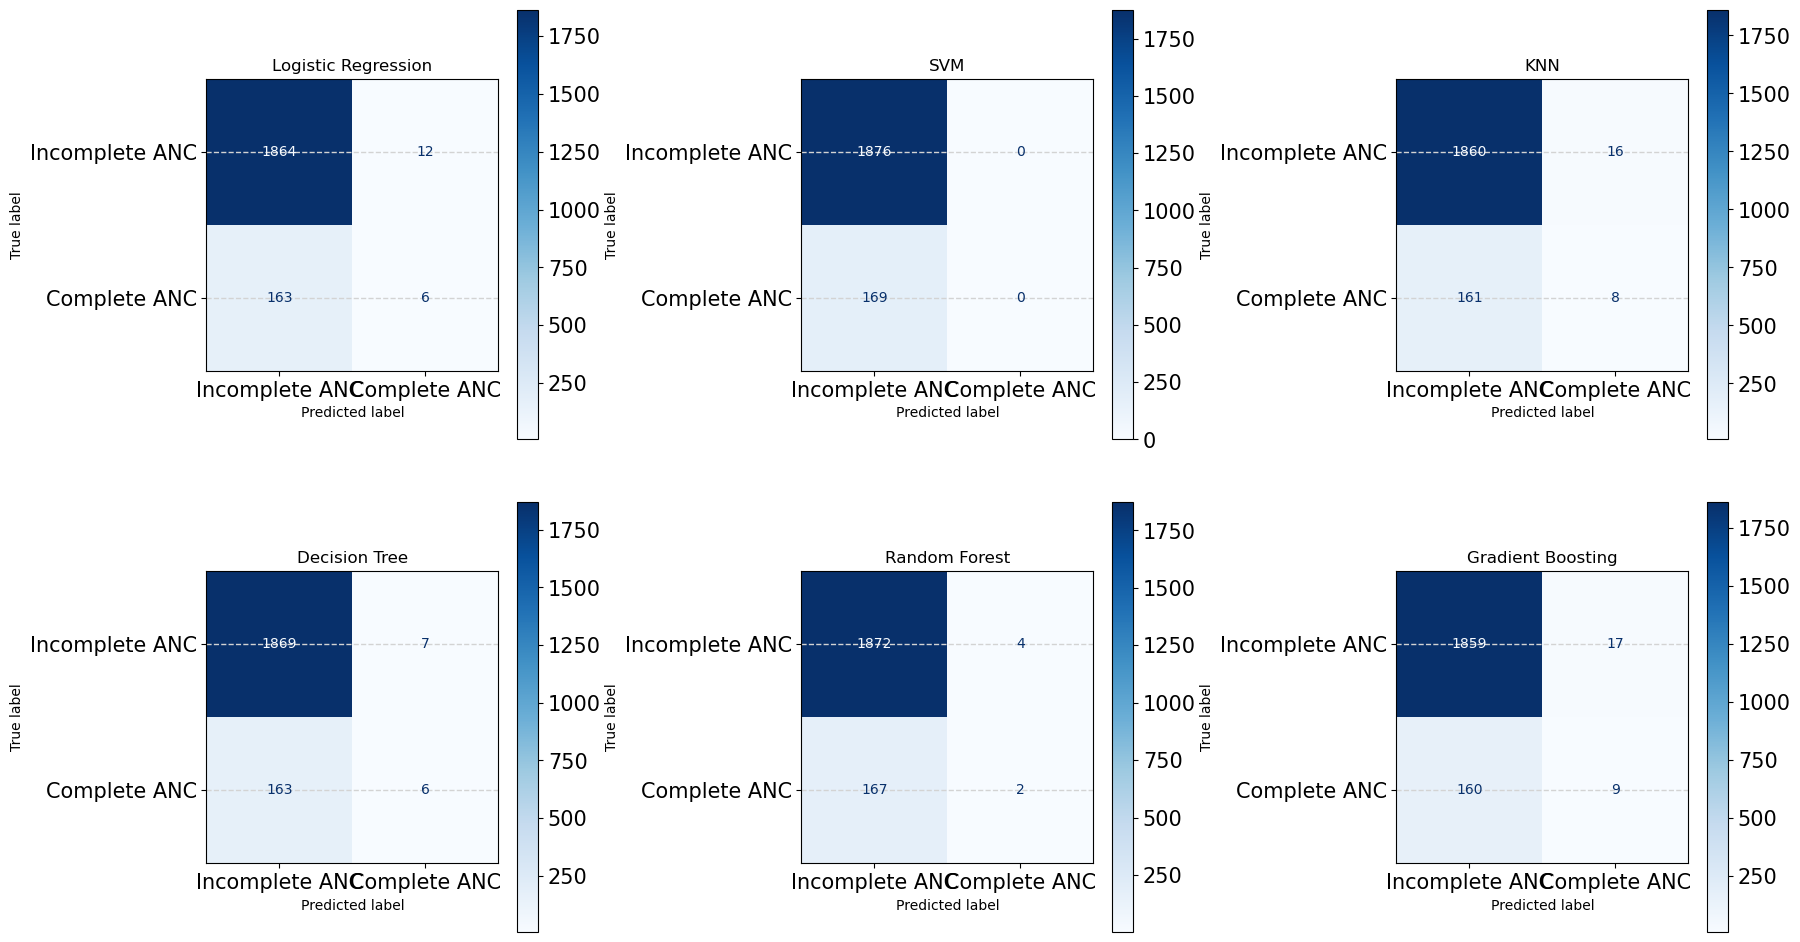

In [40]:
# Step 1: Clean y_test and map string labels to integers
y_test_clean = pd.Series(y_test).astype(str).str.strip().map({
    'incomplete ANC visits': 0,
    'complete ANC visits': 1
})

# Step 2: Define model names and their predictions
model_names = ['Logistic Regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
model_preds = [y_pred_lr, y_pred_sv, y_pred_knn, y_pred_dt, y_pred_rf, y_pred_Gb]

# Step 3: Clean and map predictions
label_mapping = {
    'incomplete ANC visits': 0,
    'complete ANC visits': 1
}
model_preds_clean = [pd.Series(pred).astype(str).str.strip().map(label_mapping) for pred in model_preds]

# Step 4: Create subplots for the confusion matrices
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, preds) in enumerate(zip(model_names, model_preds_clean)):
    cm = confusion_matrix(y_test_clean, preds)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Incomplete ANC', 'Complete ANC'])
    disp.plot(ax=axes[i], cmap='Blues', values_format='d')
    axes[i].set_title(name)

plt.tight_layout()
plt.show()

In [43]:
# List of model names and corresponding predictions
model_names = ['Logistic Regression', 'SVM', 'KNN', 'Decision Tree', 'Random Forest', 'Gradient Boosting']
model_preds = [y_pred_lr, y_pred_sv, y_pred_knn, y_pred_dt, y_pred_rf, y_pred_Gb]

# Clean and map y_test to integers
y_test_clean = pd.Series(y_test).astype(str).str.strip().map({
    'incomplete ANC visits': 0,
    'complete ANC visits': 1
})

# Function to clean and map predictions
def clean_and_map(preds):
    return pd.Series(preds).astype(str).str.strip().map({
        'incomplete ANC visits': 0,
        'complete ANC visits': 1
    })

# Apply cleaning function to all model predictions
model_preds_cleaned = [clean_and_map(preds) for preds in model_preds]

# Labels for display
label_mapping = {0: 'Incomplete ANC', 1: 'Complete ANC'}

# Loop through each model and display confusion matrix as a table
for name, preds in zip(model_names, model_preds_cleaned):
    cm = confusion_matrix(y_test_clean, preds)
    cm_df = pd.DataFrame(cm, 
                         index=[f"Actual: {label_mapping[i]}" for i in range(2)],
                         columns=[f"Predicted: {label_mapping[i]}" for i in range(2)])
    
    print(f"\n{name} Confusion Matrix")
    print(cm_df)


Logistic Regression Confusion Matrix
                        Predicted: Incomplete ANC  Predicted: Complete ANC
Actual: Incomplete ANC                       1864                       12
Actual: Complete ANC                          163                        6

SVM Confusion Matrix
                        Predicted: Incomplete ANC  Predicted: Complete ANC
Actual: Incomplete ANC                       1876                        0
Actual: Complete ANC                          169                        0

KNN Confusion Matrix
                        Predicted: Incomplete ANC  Predicted: Complete ANC
Actual: Incomplete ANC                       1860                       16
Actual: Complete ANC                          161                        8

Decision Tree Confusion Matrix
                        Predicted: Incomplete ANC  Predicted: Complete ANC
Actual: Incomplete ANC                       1869                        7
Actual: Complete ANC                          163            

# LIME and SHAP Explanation 

In [44]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

Text(0.5, 0.98, 'Top 5 and Bottom 5 Features by Random Forest Importance')

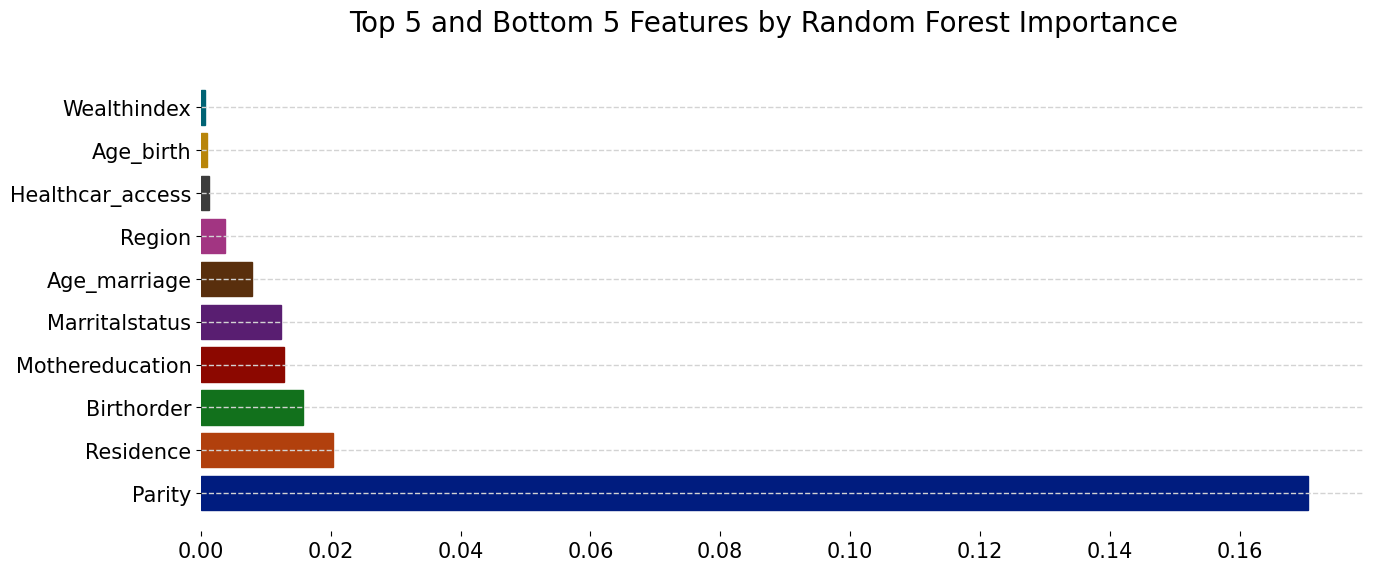

In [53]:
# Step 1: Use Random Forest model (index 4 in your trained_models list)
rf_model = trained_models[4]["model"]["clf"]

# Step 2: Get the importances and match them with actual features
importances = rf_model.feature_importances_
feature_names = np.array(current_data.columns)

# Step 3: Only keep the part of importances that matches the feature length
importances = importances[:len(feature_names)]

# Step 4: Get indices of top 5 and bottom 5 features
sorted_idx = np.argsort(importances)
top_5_idx = sorted_idx[-5:]
bottom_5_idx = sorted_idx[:5]
final_idx = np.concatenate((bottom_5_idx, top_5_idx))

# Step 5: Plot
plt.figure(figsize=(15, 6))
selected_features = feature_names[final_idx]
selected_importances = importances[final_idx]

color_list = sns.color_palette("dark", len(selected_features))
bars = plt.barh(selected_features[::-1], selected_importances[::-1])

for i, bar in enumerate(bars):
    bar.set_color(color_list[i])
    plt.box(False)

plt.suptitle("Top 5 and Bottom 5 Features by Random Forest Importance", fontsize=20, fontweight="normal")

⚠️ Skipping Decision Tree: no feature importance or coefficients available.
⚠️ Skipping Gradient Boosting: no feature importance or coefficients available.


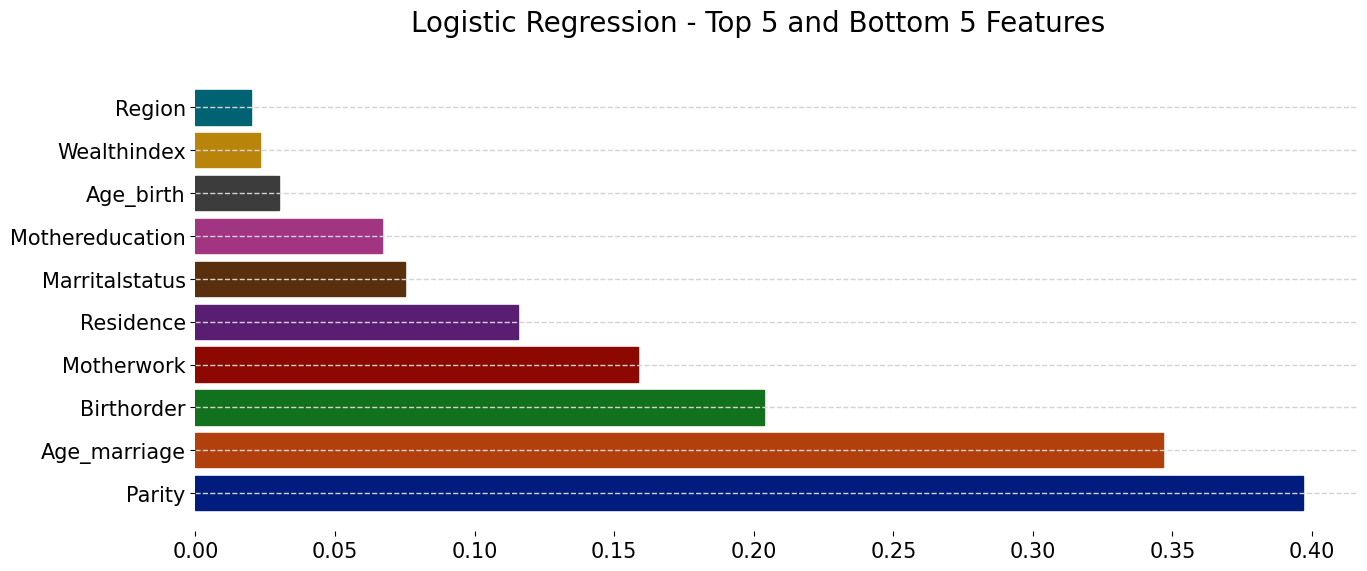

In [45]:
# Define model indices (excluding Random Forest)
model_indices = {
    "Decision Tree": 3,
    "Gradient Boosting": 5,
    "Logistic Regression": 1
}

# Loop through each model
for model_name, model_idx in model_indices.items():
    model = trained_models[model_idx]["model"]["clf"]
    feature_names = np.array(current_data.columns)

    # Handle feature importance or coefficients
    if hasattr(model, "coef_"):
        # Logistic Regression
        importances = np.abs(model.coef_[0])
    elif hasattr(model, "feature_importances_"):
        # Tree-based models
        importances = model.feature_importances_
    else:
        print(f"⚠️ Skipping {model_name}: no feature importance or coefficients available.")
        continue  # Skip unsupported models

    # Limit importances to number of actual features
    importances = importances[:len(feature_names)]

    # Get indices of top 5 and bottom 5 features
    sorted_idx = np.argsort(importances)
    top_5_idx = sorted_idx[-5:]
    bottom_5_idx = sorted_idx[:5]
    final_idx = np.concatenate((bottom_5_idx, top_5_idx))

    # Plotting
    plt.figure(figsize=(15, 6))
    selected_features = feature_names[final_idx]
    selected_importances = importances[final_idx]
    color_list = sns.color_palette("dark", len(selected_features))
    bars = plt.barh(selected_features[::-1], selected_importances[::-1])

    for i, bar in enumerate(bars):
        bar.set_color(color_list[i])
    plt.box(False)

    plt.suptitle(f"{model_name} - Top 5 and Bottom 5 Features", fontsize=20, fontweight="normal")
    plt.show()